<a href="https://colab.research.google.com/github/nguyentuanphong0510/Machine-Learning/blob/main/BTTrenLop_Buoi01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hệ số chặn (Intercept): 463.81
Hệ số góc (Slope): 25.39
MSE: 41768.68
R^2 score: 0.95

Hệ số chặn (Intercept): 325.32
Hệ số góc cho các biến [Diện tích, Số phòng ngủ, Khoảng cách]: [ 19.81720451 148.35273502 -25.12335354]
MSE (Đa biến): 8652.24
R^2 score (Đa biến): 0.98


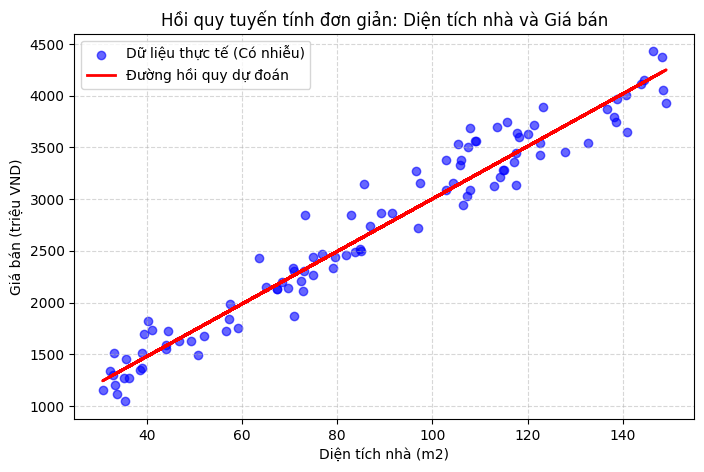

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Bài 1. Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).
# 1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên Diện tích nhà.
# 2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
# 3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.

# Cố định dữ liệu sinh ra mỗi lần giống nhau
np.random.seed(42)
# Tạo 500 mẫu dữ liệu
n_samples = 500
dien_tich = np.random.uniform(30, 150, (n_samples, 1)) # Diện tích từ 30m2 đến 150m
# Giả sử giá nhà cơ bản = 25 triệu/m2 + hệ số chặn 500 triệu + ĐỘ NHIỄU CAO HƠN (np.random.normal)
gia_ban = 500 + 25 * dien_tich + np.random.normal(0, 200, (n_samples, 1))

# Chia tập huấn luyện và kiểm tra (80% train, 20% test)
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(dien_tich, gia_ban, test_size=0.2, random_state=42)

# Huấn luyện mô hình
model_don = LinearRegression()
model_don.fit(X_train_1, y_train_1)

# Dự đoán & Đánh giá
y_pred_1 = model_don.predict(X_test_1)
mse_1 = mean_squared_error(y_test_1, y_pred_1)
r2_1 = r2_score(y_test_1, y_pred_1)

print(f"Hệ số chặn (Intercept): {model_don.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope): {model_don.coef_[0][0]:.2f}")
print(f"MSE: {mse_1:.2f}")
print(f"R^2 score: {r2_1:.2f}\n")


# Thêm 2 biến mới:
# - so_phong_ngu: Số phòng ngủ (từ 1 đến 5 phòng)
# - khoang_cach: Khoảng cách đến trung tâm thành phố (km, từ 1 đến 20 km)
so_phong_ngu = np.random.randint(1, 6, (n_samples, 1))
khoang_cach = np.random.uniform(1, 20, (n_samples, 1))

# Tạo tập dữ liệu dạng bảng (DataFrame) gồm 3 biến đầu vào: [Diện tích, Số phòng ngủ, Khoảng cách]
X_multi = np.hstack((dien_tich, so_phong_ngu, khoang_cach))

# Giá nhà giả định phụ thuộc vào cả 3 yếu tố (diện tích tăng giá, phòng ngủ tăng giá, khoảng cách làm giảm giá)
gia_ban_multi = (
    300
    + 20 * dien_tich
    + 150 * so_phong_ngu
    - 25 * khoang_cach
    + np.random.normal(0, 100, (n_samples, 1))
)

# Chia tập dữ liệu cho mô hình đa biến
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, gia_ban_multi, test_size=0.2, random_state=42)

# Huấn luyện mô hình đa biến
model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

# Dự đoán & Đánh giá
y_pred_m = model_multi.predict(X_test_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
r2_m = r2_score(y_test_m, y_pred_m)

print(f"Hệ số chặn (Intercept): {model_multi.intercept_[0]:.2f}")
print(f"Hệ số góc cho các biến [Diện tích, Số phòng ngủ, Khoảng cách]: {model_multi.coef_[0]}")
print(f"MSE (Đa biến): {mse_m:.2f}")
print(f"R^2 score (Đa biến): {r2_m:.2f}")

#
plt.figure(figsize=(8, 5))
plt.scatter(X_test_1, y_test_1, color="blue", alpha=0.6, label="Dữ liệu thực tế (Có nhiễu)")
plt.plot(X_test_1, y_pred_1, color="red", linewidth=2, label="Đường hồi quy dự đoán")
plt.title("Hồi quy tuyến tính đơn giản: Diện tích nhà và Giá bán")
plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Kết quả đánh giá
Độ chính xác (Accuracy): 88.75%
Ma trận nhầm lẫn (Confusion Matrix):
[[33  4]
 [ 5 38]]


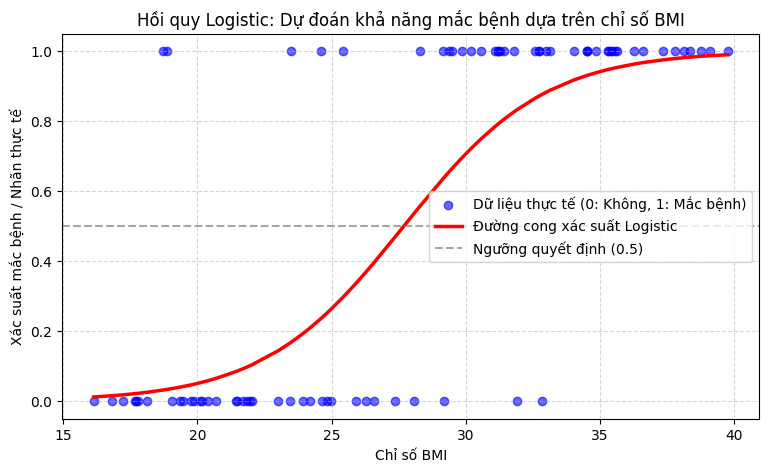

In [8]:
# Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI Giả sử có một tập dữ liệu với các thông tin sau:
#- BMI: Chỉ số khối cơ thể của bệnh nhân (Body Mass Index).
#- Mắc bệnh: Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
# 1. - Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic (BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
# 2. - Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.
# 3. - Huấn luyện mô hình trên tập dữ liệu mẫu.
# 4. - Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra.
# 5. - Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn.
# 6. - Trực quan hóa dữ liệu và đường hồi quy logistic.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42) # cố định dữ liệu
n_samples=400 #tạo dữ liệu
BMI=np.random.uniform(16,40,(n_samples,1))#BMI dao động trong khoảng 16 tới 40
# Giả sử: BMI càng cao thì tỉ lể mắc bệnh càng lớn, 28 là chỉ số có thể mắc bệnh cao
z=0.4*(BMI-28)
p=1/(1+np.exp(-z))
#tạo nhãn 0:không bệnh, 1:bệnh dựa vô xác suất p
macbenh=np.random.binomial(1,p).reshape(-1,1)
# chia tập huấn luyện thành 80% train và 20% test
(X_train,X_test,y_train,y_test)=train_test_split(BMI,macbenh, test_size=0.2,random_state= 42)

model=LogisticRegression()
model.fit(X_train,y_train.ravel())

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1] # Dự đoán xác suất mắc bệnh (lấy xác suất thuộc lớp 1)
# đánh giá hiêu quả
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Kết quả đánh giá")
print(f"Độ chính xác (Accuracy): {accuracy * 100:.2f}%")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)



# trực quan hóa và đường cong dữ liệu

plt.figure(figsize=(9, 5))

# Vẽ các điểm dữ liệu thực tế trên tập test (0 ở dưới, 1 ở trên)
plt.scatter(X_test, y_test, color="blue", alpha=0.6, label="Dữ liệu thực tế (0: Không, 1: Mắc bệnh)")

# Sắp xếp lại X_test để vẽ đường cong mượt mà không bị gấp khúc
sort_idx = X_test.ravel().argsort()
X_test_sorted = X_test.ravel()[sort_idx]
y_pred_proba_sorted = y_pred_proba[sort_idx]

# Vẽ đường cong Sigmoid thể hiện xác suất dự đoán
plt.plot(X_test_sorted, y_pred_proba_sorted, color="red", linewidth=2.5, label="Đường cong xác suất Logistic")

# Vẽ đường ngưỡng quyết định 0.5
plt.axhline(0.5, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng quyết định (0.5)")

plt.title("Hồi quy Logistic: Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh / Nhãn thực tế")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

 kết quả đánh giá mô hình
Hệ số góc (Coefficients) cho các biến: [ 0.4447578   0.01683623 -0.02814968]
Hệ số chặn (Intercept): 0.0173
Mean Squared Error (MSE): 0.6589
R^2 score: 0.4972


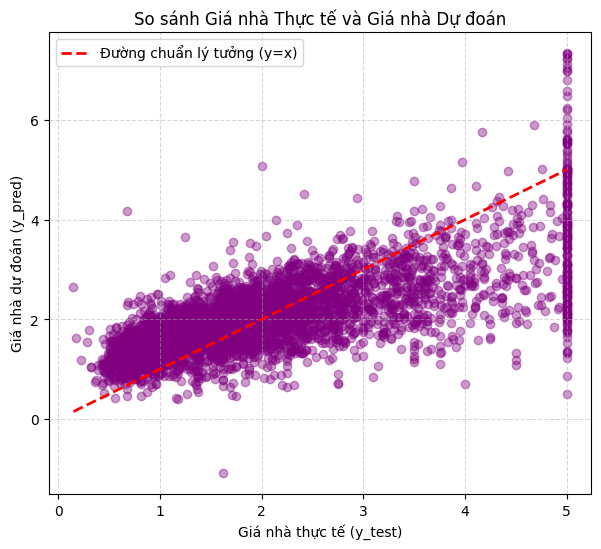

In [3]:
# Bài 3. Hãy chọn 1 bộ dữ liệu tùy ý (HD: có thể tham khảo trên các trang mạng, ví dụ như Kaggle)
#thực hiện các bước cần thiết để có được mô hình hồi qui ứng với bộ dữ liệu đã chọn.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

california=fetch_california_housing(as_frame=True)
df=california.frame
print(df.head())
# Biến đầu vào
X = df[['MedInc', 'HouseAge', 'AveRooms']]
# Biến đầu ra
y = df['MedHouseVal']
# Chia tập dữ liệu thành 80% huấn luyện và 20% kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#xây dựng và huấn luyện mô hình hồi quy
model = LinearRegression()
model.fit(X_train, y_train)

#dự đoán và đánh giá mô hình
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n kết quả đánh giá mô hình")
print(f"Hệ số góc (Coefficients) cho các biến: {model.coef_}")
print(f"Hệ số chặn (Intercept): {model.intercept_:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 score: {r2:.4f}")


plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, color="purple", alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", linewidth=2, label="Đường chuẩn lý tưởng (y=x)")
plt.title("So sánh Giá nhà Thực tế và Giá nhà Dự đoán")
plt.xlabel("Giá nhà thực tế (y_test)")
plt.ylabel("Giá nhà dự đoán (y_pred)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()